# 01: Explore the data

What is in the kit, and what the problem looks like in the data:
1. the flights in the kit
2. the map, the routes and the landing sites
3. **constant** M1 friction: one mission at 6 health levels
4. outcome statistics over the full datasets (manifests)
5. **growing** friction in flight, and the health estimate z(t)
6. the **pair coupling** M1 = M4
7. the **counterfactual** branches: the decision problem itself

Docs: `../docs/01_PROBLEM_AND_FORMALIZATION.md` (problem), `../docs/05_DATA_DICTIONARY.md` (every field).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from hexakit import io
pd.set_option("display.width", 200, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
idx = io.flight_index()
idx.groupby(["subset", "outcome"]).size().unstack(fill_value=0)

outcome,FAIL,MISSION PASS
subset,,
counterfactual_cf,6,6
fixed_M1_v2,17,13
growing_M1_eval,16,0
growing_M1_v3,8,10


## 1. The flights in the kit
One row per flight. Within a family, only the health (or the action) changes.

In [2]:
cols = ["subset", "flight_id", "family_id", "route_id", "mass_kg", "wind_speed_ms", "friction_factor",
        "fault_onset_s", "fault_d_end_target", "friction_end_x", "cf_branch", "nominal_duration_s", "outcome", "Failed checks"]
idx[cols]

,subset,flight_id,family_id,route_id,mass_kg,wind_speed_ms,friction_factor,fault_onset_s,fault_d_end_target,friction_end_x,cf_branch,nominal_duration_s,outcome,Failed checks
0,fixed_M1_v2,F1020,S173,97,2.126991,1.174257,1.000000,NaN,NaN,NaN,NaN,280.1400,MISSION PASS,NaN
1,fixed_M1_v2,F1021,S173,97,2.126991,1.174257,1.504238,NaN,NaN,NaN,NaN,280.1400,FAIL,Envelope / divergence (F1); Landing (F7)
2,fixed_M1_v2,F1022,S173,97,2.126991,1.174257,3.153521,NaN,NaN,NaN,NaN,280.1400,FAIL,Envelope / divergence (F1); Landing (F7)
3,fixed_M1_v2,F1125,S208,60,1.716568,0.023264,1.000000,NaN,NaN,NaN,NaN,305.3825,MISSION PASS,NaN
4,fixed_M1_v2,F1126,S208,60,1.716568,0.023264,1.573883,NaN,NaN,NaN,NaN,305.3825,MISSION PASS,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,counterfactual_cf,FC0063,S496,63,2.189392,1.266313,1.000000,81.439375,6.0,2.881716,alloc_payload,325.7575,MISSION PASS,NaN
72,counterfactual_cf,FC0080,S501,47,1.849649,0.373501,1.000000,109.518125,6.0,4.404046,none,438.0725,FAIL,Ground impact (F6b); Landing (F7); Corridor (F...
73,counterfactual_cf,FC0081,S501,47,1.849649,0.373501,1.000000,109.518125,6.0,2.791050,alloc,438.0725,MISSION PASS,NaN
74,counterfactual_cf,FC0082,S501,47,1.849649,0.373501,1.000000,109.518125,6.0,4.150148,payload,438.0725,FAIL,Ground impact (F6b); Landing (F7); Corridor (F8)


## 2. Map, routes and landing sites
Building footprints from OpenStreetMap on a 2 m grid. A = start/home, B = goal; L1–L4 = placeholder landing sites.
151 alternative A→B routes: grey = train routes, orange = held-out test routes, black = the shortest (benchmark).

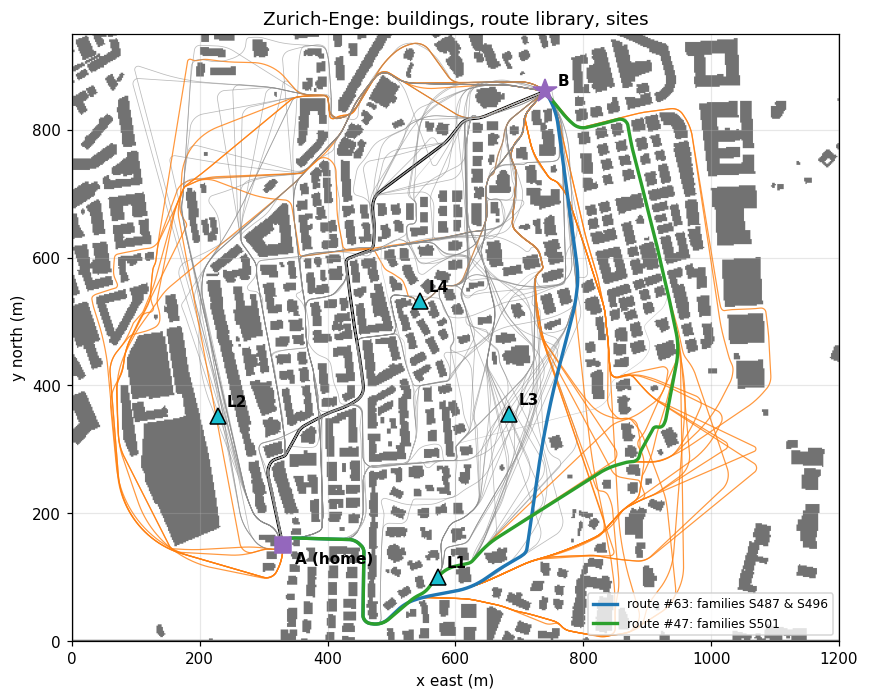

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
benchmark,1.0,975.0,NaN,975.0,975.0,975.0,975.0,975.0
test,33.0,1555.0,112.0,1272.0,1477.0,1561.0,1638.0,1753.0
train,113.0,1182.0,139.0,975.0,1057.0,1198.0,1278.0,1578.0
unused,4.0,1178.0,191.0,1036.0,1081.0,1108.0,1205.0,1460.0


In [3]:
m, routes = io.load_map(), io.load_routes()
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(m["grid"], origin="upper", extent=(0, m["width_m"], 0, m["height_m"]), cmap="Greys", vmin=0, vmax=1.6)
for rid, r in routes.items():
    st = dict(train=dict(c="0.55", lw=0.5, alpha=0.6), test=dict(c="tab:orange", lw=0.8, alpha=0.8),
              benchmark=dict(c="k", lw=2), unused=dict(c="0.8", lw=0.4)).get(r["split"])
    ax.plot(*r["xy"].T, **st)
for fams, c in [(("S487", "S496"), "tab:blue"), (("S501",), "tab:green")]:
    rid = int(idx[idx.family_id == fams[0]].route_id.iloc[0])
    ax.plot(*routes[rid]["xy"].T, c=c, lw=2.2, label=f"route #{rid}: families {' & '.join(fams)}")
s = m["sites"]
ax.plot(*s["A_start_home"], "s", c="tab:purple", ms=10); ax.annotate("A (home)", s["A_start_home"], xytext=(8, -12), textcoords="offset points", weight="bold")
ax.plot(*s["B_goal_dataset"], "*", c="tab:purple", ms=16); ax.annotate("B", s["B_goal_dataset"], xytext=(8, 4), textcoords="offset points", weight="bold")
for k, xy in s["landing_sites"].items():
    if k.startswith("L"):
        ax.plot(*xy, "^", c="tab:cyan", mec="k", ms=10); ax.annotate(k, xy, xytext=(6, 6), textcoords="offset points", weight="bold")
ax.set(xlabel="x east (m)", ylabel="y north (m)", title="Zurich-Enge: buildings, route library, sites"); ax.legend(loc="lower right", fontsize=8)
plt.show()
pd.read_csv("../data/routes/routes_summary.csv").groupby("split").length_m.describe().round(0)

## 3. Constant M1 friction: one mission at 6 health levels (family S496)
Same route, mass, wind, configuration; only M1's friction changes (1× … 7×). Watch M1's command climb toward the
840 rad/s ceiling while its **actual** speed falls, and M4 (the opposite motor) go the other way. The 5× flight
diverges at ~150 s and the 7× flight right after take-off; the 3.1× flight fails at the landing.

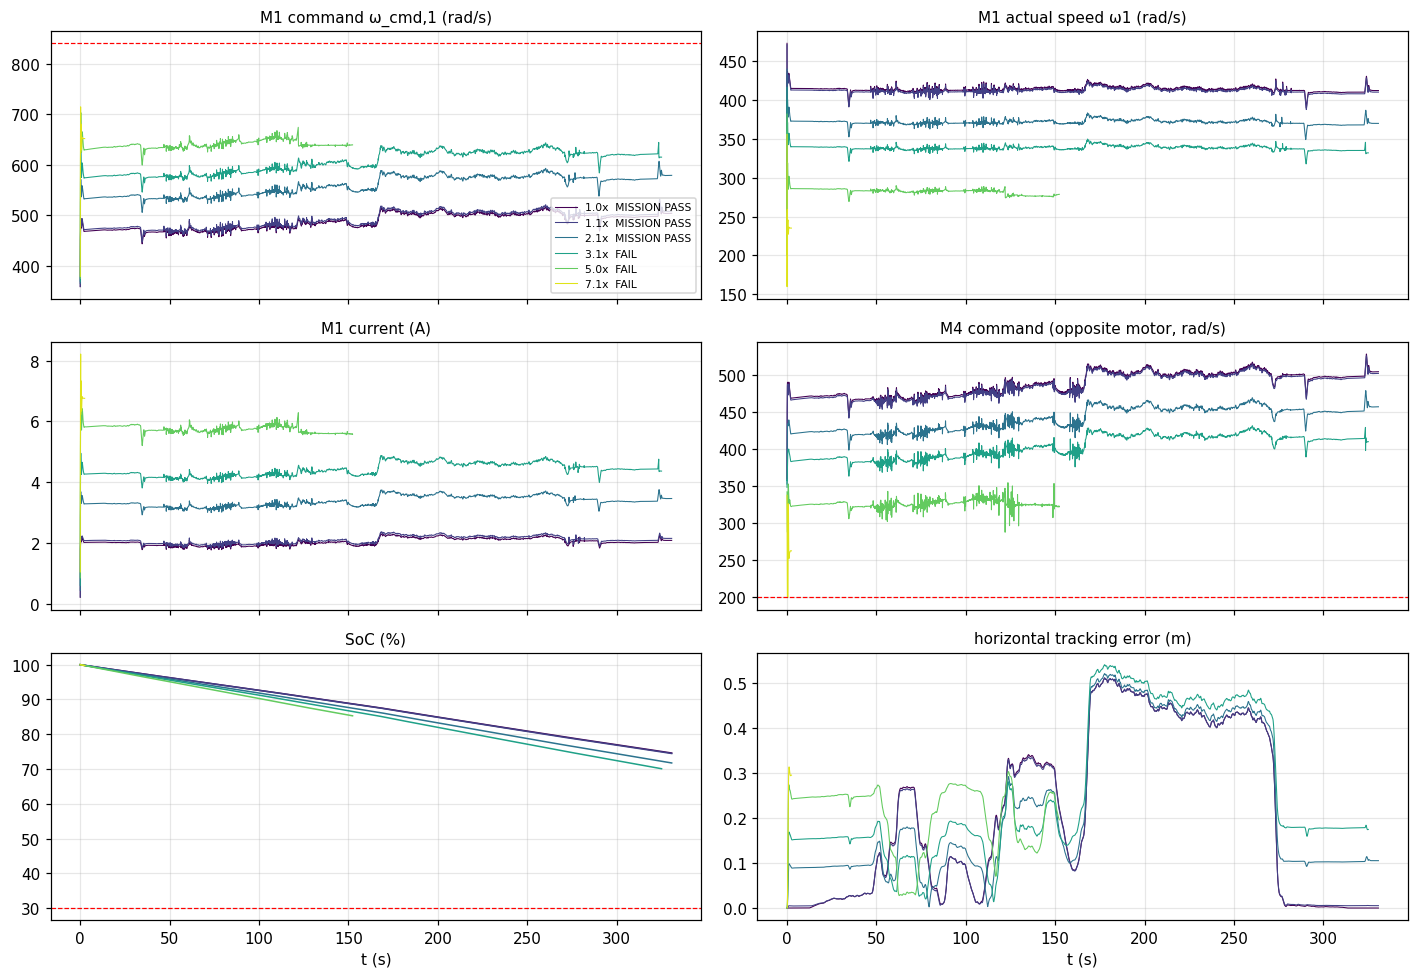

,flight_id,friction_factor,outcome,Failed checks,Final SOC (%),Max deviation (m),diag: M1 at 840 (s),diag: M1 min headroom (rad/s)
18,F2076,1.000000,MISSION PASS,NaN,74.589870,0.114530,0.0,311.579627
19,F2077,1.052485,MISSION PASS,NaN,74.451304,0.117305,0.0,307.383343
20,F2078,2.119682,MISSION PASS,NaN,71.727135,0.210793,0.0,232.639754
21,F2079,3.081659,FAIL,Envelope / divergence (F1); Landing (F7),NaN,NaN,0.0,194.511943
22,F2080,4.960315,FAIL,Envelope / divergence (F1); Altitude control (...,NaN,NaN,0.0,164.894770
23,F2081,7.110150,FAIL,Envelope / divergence (F1); Landing (F7),NaN,NaN,NaN,NaN


In [4]:
fam = idx[(idx.family_id == "S496") & (idx.subset == "fixed_M1_v2")].sort_values("friction_factor")
fig, axs = plt.subplots(3, 2, figsize=(13, 9), sharex=True); axs = axs.ravel()
cmap = plt.cm.viridis(np.linspace(0, 0.95, len(fam)))
for c, (_, row) in zip(cmap, fam.iterrows()):
    f = io.load_flight(row.flight_id); t = f["t"]; lab = f"{row.friction_factor:.1f}x  {row.outcome}"
    axs[0].plot(t, f["omega_cmd_rads"][:, 0], c=c, lw=0.7, label=lab)
    axs[1].plot(t, f["rotor_speed_rads"][:, 0], c=c, lw=0.7)
    axs[2].plot(t, f["motor_current_A"][:, 0], c=c, lw=0.7)
    axs[3].plot(t, f["omega_cmd_rads"][:, 3], c=c, lw=0.7)
    axs[4].plot(t, 100 * f["soc"], c=c, lw=1)
    axs[5].plot(t, np.linalg.norm(f["tracking_error_m"][:, :2], axis=1), c=c, lw=0.7)
for a, ttl in zip(axs, ["M1 command ω_cmd,1 (rad/s)", "M1 actual speed ω1 (rad/s)", "M1 current (A)",
                        "M4 command (opposite motor, rad/s)", "SoC (%)", "horizontal tracking error (m)"]):
    a.set_title(ttl, fontsize=10)
axs[0].axhline(840, c="r", ls="--", lw=0.8); axs[3].axhline(200, c="r", ls="--", lw=0.8); axs[4].axhline(30, c="r", ls="--", lw=0.8)
axs[0].legend(fontsize=7, loc="lower right"); axs[4].set_xlabel("t (s)"); axs[5].set_xlabel("t (s)")
plt.tight_layout(); plt.show()
fam[["flight_id", "friction_factor", "outcome", "Failed checks", "Final SOC (%)", "Max deviation (m)", "diag: M1 at 840 (s)", "diag: M1 min headroom (rad/s)"]]

## 4. Outcome statistics over the full datasets
The manifests have every flight (no time series). DB_dev v2: 1,164 flights at constant friction, 344 families,
random configurations (mass, LQR, allocation, speed, wind).

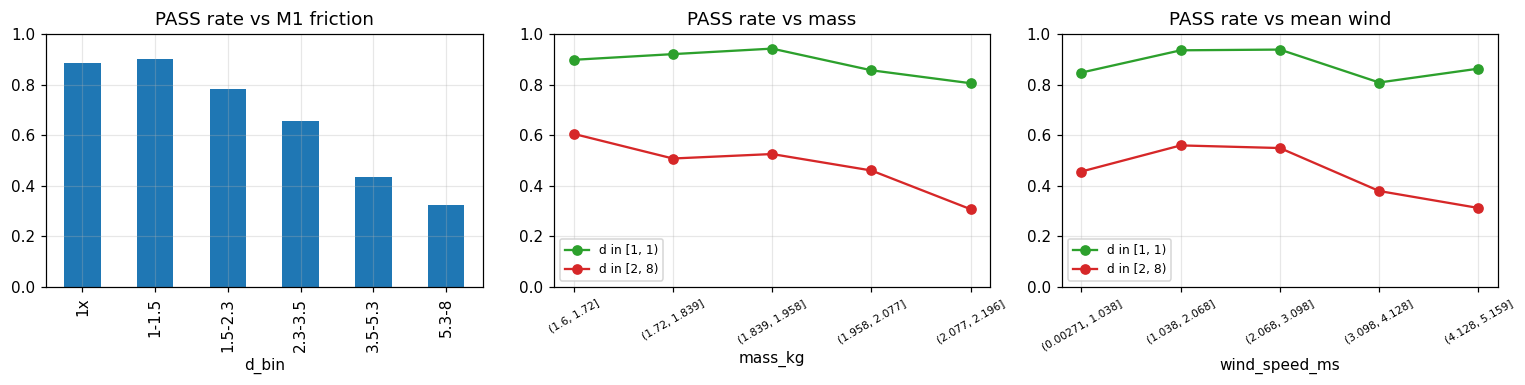

Most frequent failure combinations (v2):


Failed checks
Envelope / divergence (F1); Landing (F7)                                                143
Envelope / divergence (F1); Altitude control (F5); Ground impact (F6b); Landing (F7)     41
SoC reserve (F8)                                                                         26
Corridor (F8)                                                                            24
Ground impact (F6b); Landing (F7); Corridor (F8)                                         19
Envelope / divergence (F1); Angular rates (F4); Landing (F7)                             19
Landing (F7); Corridor (F8); Destination and deadline (F9)                               15
Envelope / divergence (F1); Altitude control (F5); Landing (F7)                          14
Name: count, dtype: int64

In [5]:
v2 = io.all_flights("dbdev_v2"); v2["pass"] = v2.outcome == "MISSION PASS"
v2["d_bin"] = pd.cut(v2.friction_factor, [0.99, 1.01, 1.52, 2.30, 3.48, 5.28, 8.01], labels=["1x", "1-1.5", "1.5-2.3", "2.3-3.5", "3.5-5.3", "5.3-8"])
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
v2.groupby("d_bin", observed=True)["pass"].mean().plot.bar(ax=axs[0], color="tab:blue"); axs[0].set(title="PASS rate vs M1 friction", ylim=(0, 1))
for lo, hi, c in [(0.99, 1.01, "tab:green"), (2.3, 8.01, "tab:red")]:
    s = v2[(v2.friction_factor >= lo) & (v2.friction_factor < hi)]
    s.groupby(pd.cut(s.mass_kg, 5), observed=True)["pass"].mean().plot(ax=axs[1], marker="o", c=c, label=f"d in [{lo:.0f}, {hi:.0f})")
    s.groupby(pd.cut(s.wind_speed_ms, 5), observed=True)["pass"].mean().plot(ax=axs[2], marker="o", c=c, label=f"d in [{lo:.0f}, {hi:.0f})")
axs[1].set(title="PASS rate vs mass", ylim=(0, 1)); axs[2].set(title="PASS rate vs mean wind", ylim=(0, 1))
for a in axs[1:]: a.tick_params(axis="x", rotation=30, labelsize=7); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Most frequent failure combinations (v2):")
v2.loc[~v2["pass"], "Failed checks"].value_counts().head(8)

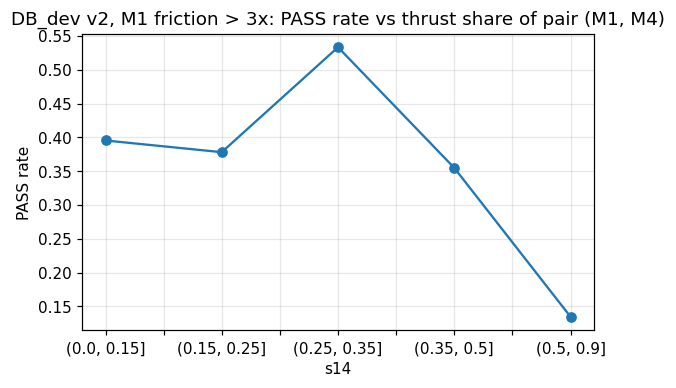

,mean,size
s14,,
"(0.0, 0.15]",0.395349,43
"(0.15, 0.25]",0.378049,82
"(0.25, 0.35]",0.533333,165
"(0.35, 0.5]",0.354839,62
"(0.5, 0.9]",0.134615,52


In [6]:
# The allocation's M1-M4 pair share vs outcome at high friction. Only a hint: s14 = 1/3 includes the anchors
# (baseline LQR, uniform allocation), and s14 is correlated with the other sampled factors; extreme shares load the
# other motors heavily. A proper analysis needs a multivariate model (pilot problem P3).
v2["s14"] = v2.alloc_shares.apply(lambda s: eval(s)[0] if isinstance(s, str) else 1/3)
hi = v2[v2.friction_factor > 3]
fig, ax = plt.subplots(figsize=(6, 3.5))
hi.groupby(pd.cut(hi.s14, [0, .15, .25, .35, .5, .9]), observed=True)["pass"].agg(["mean", "size"])["mean"].plot(marker="o", ax=ax)
ax.set(title="DB_dev v2, M1 friction > 3x: PASS rate vs thrust share of pair (M1, M4)", ylabel="PASS rate", xlabel="s14"); plt.show()
hi.groupby(pd.cut(hi.s14, [0, .15, .25, .35, .5, .9]), observed=True)["pass"].agg(["mean", "size"])

## 5. Growing friction in flight and the health estimate z(t)
DB_dev v3: each family has a healthy flight, a fault growing from 1×, and a fault growing from a pre-worn 1.5–3×.
The health traces give z(t) of three trained encoders (1 s bins). z never saw the friction.

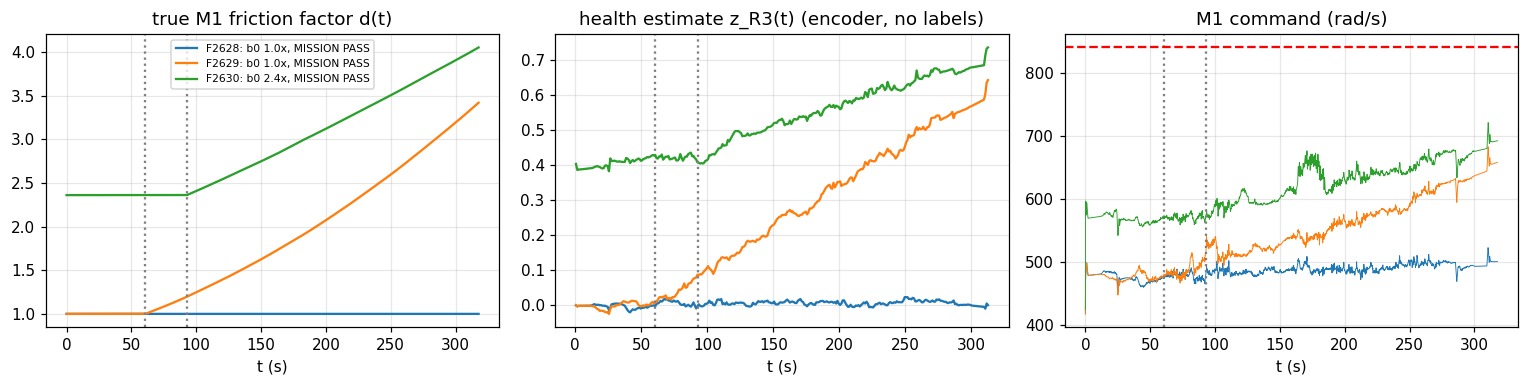

In [7]:
tr = io.load_health_traces("dbdev_v3")
fam = idx[(idx.subset == "growing_M1_v3") & (idx.family_id == "S695")]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for _, row in fam.iterrows():
    f, z = io.load_flight(row.flight_id), io.trace_of(tr, row.flight_id)
    lab = f"{row.flight_id}: b0 {row.friction_factor:.1f}x, {row.outcome}"
    axs[0].plot(f["t"], f["d"], label=lab); axs[1].plot(z["t"], z["z_R3"][:, 0]); axs[2].plot(f["t"], f["omega_cmd_rads"][:, 0], lw=0.6)
    if np.isfinite(row.fault_onset_s): [a.axvline(row.fault_onset_s, ls=":", c="0.5") for a in axs]
axs[0].set(title="true M1 friction factor d(t)", xlabel="t (s)"); axs[0].legend(fontsize=7)
axs[1].set(title="health estimate z_R3(t) (encoder, no labels)", xlabel="t (s)")
axs[2].set(title="M1 command (rad/s)", xlabel="t (s)"); axs[2].axhline(840, c="r", ls="--")
plt.tight_layout(); plt.show()

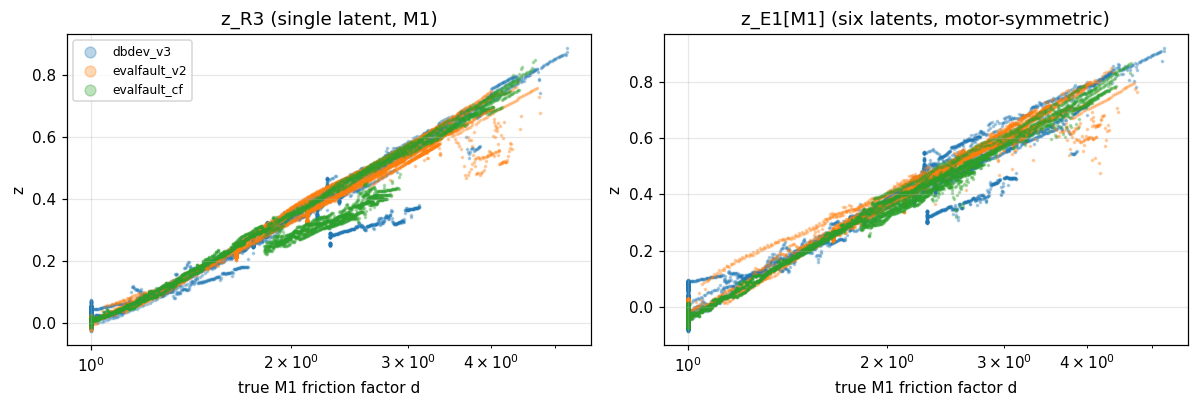

In [8]:
# z against the true friction, all kit flights with traces: monotone but concave in log d
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ds, c in [("dbdev_v3", "tab:blue"), ("evalfault_v2", "tab:orange"), ("evalfault_cf", "tab:green")]:
    t_ = io.load_health_traces(ds)
    axs[0].scatter(t_["d"], t_["z_R3"][:, 0], s=2, alpha=0.3, c=c, label=ds)
    axs[1].scatter(t_["d"], t_["z_E1"][:, 0], s=2, alpha=0.3, c=c)
for a, ttl in zip(axs, ["z_R3 (single latent, M1)", "z_E1[M1] (six latents, motor-symmetric)"]):
    a.set(xscale="log", xlabel="true M1 friction factor d", ylabel="z", title=ttl)
axs[0].legend(markerscale=5, fontsize=8); plt.tight_layout(); plt.show()

## 6. The pair coupling: M1 and M4 always turn at the same speed in balanced flight
Whatever the allocation, opposite motors (M1/M4, M2/M5, M3/M6) end up at the same **actual** speed in steady
flight. Their commands differ, because the friction-worn M1 needs a larger command for the same speed.
(Proof in doc 01 §1.5a.)

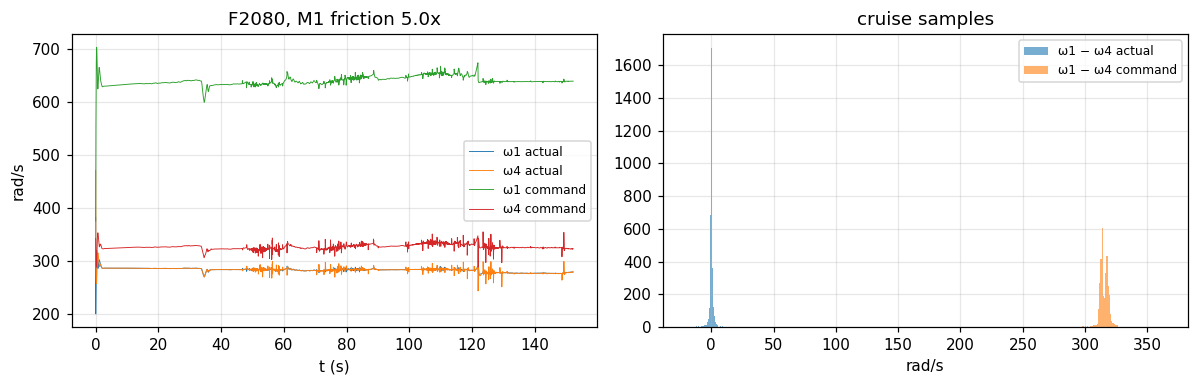

In [9]:
f = io.load_flight("F2080")  # constant 5x friction
w, c = f["rotor_speed_rads"], f["omega_cmd_rads"]; air = f["phase"] == 3
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(f["t"], w[:, 0], lw=0.6, label="ω1 actual"); axs[0].plot(f["t"], w[:, 3], lw=0.6, label="ω4 actual")
axs[0].plot(f["t"], c[:, 0], lw=0.6, label="ω1 command"); axs[0].plot(f["t"], c[:, 3], lw=0.6, label="ω4 command"); axs[0].legend(fontsize=8)
axs[0].set(title=f"F2080, M1 friction {f['d'][0]:.1f}x", xlabel="t (s)", ylabel="rad/s")
axs[1].hist((w[air, 0] - w[air, 3]), bins=80, alpha=0.6, label="ω1 − ω4 actual"); axs[1].hist((c[air, 0] - c[air, 3]), bins=80, alpha=0.6, label="ω1 − ω4 command")
axs[1].set(title="cruise samples", xlabel="rad/s"); axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. The counterfactual branches: the decision problem itself
Each family is flown 4 times, **bit-identical until t_d**, then: no action / payload drop (0.15 kg) /
allocation that unloads the M1–M4 pair / both. One physical wear rate per family. This is the only data where an
action's effect on damage and outcome is causal.

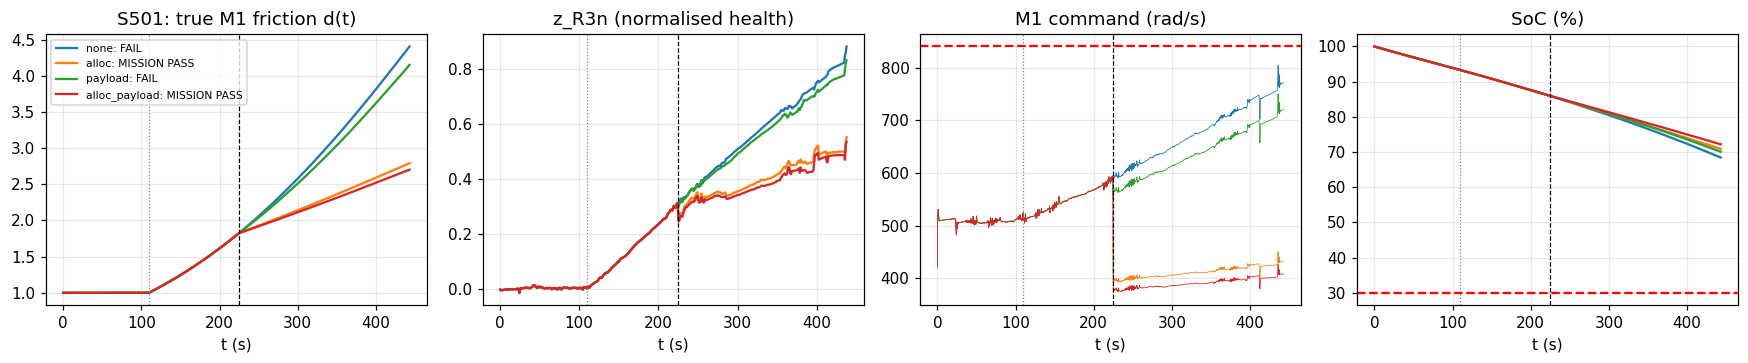

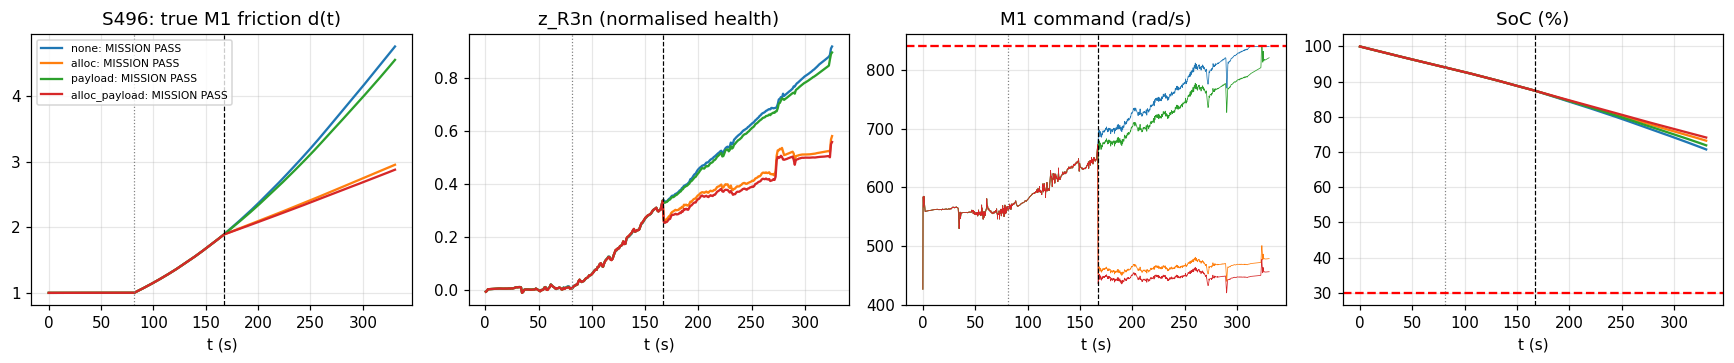

Full counterfactual set (30 families):


,PASS,d_end_median,soc_end_median
cf_branch,,,
alloc,0.90,2.80,56.13
alloc_payload,0.93,2.71,58.00
none,0.63,4.42,52.26
payload,0.70,4.16,54.66


In [10]:
trc = io.load_health_traces("evalfault_cf")
for famid in ["S501", "S496"]:
    fam = idx[(idx.subset == "counterfactual_cf") & (idx.family_id == famid)]
    fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
    for _, row in fam.iterrows():
        f, z = io.load_flight(row.flight_id), io.trace_of(trc, row.flight_id)
        lab = f"{row.cf_branch}: {row.outcome}"
        axs[0].plot(f["t"], f["d"], label=lab); axs[1].plot(z["t"], z["z_R3n"][:, 0])
        axs[2].plot(f["t"], f["omega_cmd_rads"][:, 0], lw=0.5); axs[3].plot(f["t"], 100 * f["soc"])
    for a in axs: a.axvline(row.cf_t_dec_s, c="k", ls="--", lw=0.8); a.axvline(row.fault_onset_s, c="0.5", ls=":", lw=0.8); a.set_xlabel("t (s)")
    axs[0].set_title(f"{famid}: true M1 friction d(t)"); axs[0].legend(fontsize=7)
    axs[1].set_title("z_R3n (normalised health)"); axs[2].set_title("M1 command (rad/s)"); axs[2].axhline(840, c="r", ls="--")
    axs[3].set_title("SoC (%)"); axs[3].axhline(30, c="r", ls="--")
    plt.tight_layout(); plt.show()
cf = io.all_flights("evalfault_cf")
print("Full counterfactual set (30 families):")
cf.groupby("cf_branch").agg(PASS=("outcome", lambda s: (s == "MISSION PASS").mean()), d_end_median=("friction_end_x", "median"),
                            soc_end_median=("Final SOC (%)", "median")).round(2)

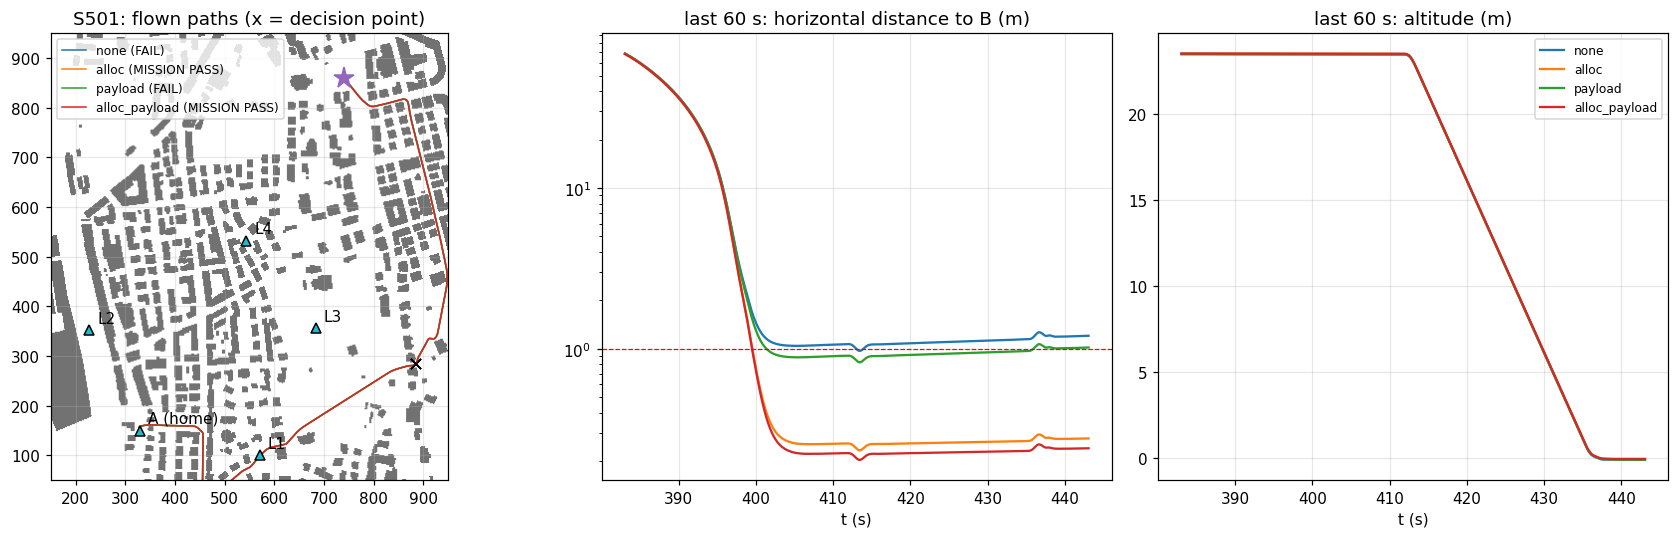

,flight_id,cf_branch,outcome,Failed checks,contact vz (m/s),contact v_xy (m/s),contact offset (m),Final SOC (%),friction_end_x
72,FC0080,none,FAIL,Ground impact (F6b); Landing (F7); Corridor (F...,-0.183250,0.023315,1.264552,68.452014,4.404046
73,FC0081,alloc,MISSION PASS,NaN,-0.175362,0.012675,0.291292,70.905214,2.791050
74,FC0082,payload,FAIL,Ground impact (F6b); Landing (F7); Corridor (F8),-0.174280,0.030632,1.065080,70.100735,4.150148
75,FC0083,alloc_payload,MISSION PASS,NaN,-0.180071,0.015322,0.251361,72.195939,2.702160


In [11]:
# Flown paths of one family: they overlap (same route); the failing branches fail at the LANDING at B
famid = "S501"; fam = idx[(idx.subset == "counterfactual_cf") & (idx.family_id == famid)]
fig, axs = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
axs[0].imshow(m["grid"], origin="upper", extent=(0, 1200, 0, 950), cmap="Greys", vmin=0, vmax=1.6)
B = np.array(m["sites"]["B_goal_dataset"])
for _, row in fam.iterrows():
    f = io.load_flight(row.flight_id); xy = io.map_xy(f); t = f["t"]
    axs[0].plot(*xy.T, lw=1, label=f"{row.cf_branch} ({row.outcome})")
    k = np.searchsorted(t, row.cf_t_dec_s); axs[0].plot(*xy[k], "kx")
    last = t > t[-1] - 60
    axs[1].plot(t[last], np.linalg.norm(xy[last] - B, axis=1), label=row.cf_branch)
    axs[2].plot(t[last], f["position_m"][last, 2], label=row.cf_branch)
axs[0].plot(*B, "*", c="tab:purple", ms=14)
for kk, xy in m["sites"]["landing_sites"].items(): axs[0].plot(*xy, "^", c="tab:cyan", mec="k"); axs[0].annotate(kk, xy, xytext=(5, 5), textcoords="offset points")
axs[0].set(xlim=(150, 950), ylim=(50, 950), title=f"{famid}: flown paths (x = decision point)"); axs[0].legend(fontsize=8)
axs[1].axhline(1, c="r", ls="--", lw=0.8); axs[1].set(title="last 60 s: horizontal distance to B (m)", xlabel="t (s)", yscale="log")
axs[2].set(title="last 60 s: altitude (m)", xlabel="t (s)"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
fam[["flight_id", "cf_branch", "outcome", "Failed checks", "contact vz (m/s)", "contact v_xy (m/s)", "contact offset (m)", "Final SOC (%)", "friction_end_x"]]

## Where to go next
- `02_pilot_optimization.ipynb`: a white-box toy optimisation (allocation design; ranking the CF actions).
- Ideas to try with this data: an outcome classifier on the manifests (P(PASS | d, mass, wind, s14, speed, …)) as a
  chance constraint; λ estimation from z histories; when to decide (the earlier, the larger the benefit but the
  noisier λ̂).